# Read in output from Gaia

In this example, we read in a set of cluster observations from Gaia, and prep for feeding into StarStream

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import astropy.units as u
import astropy.coordinates as coord
from astropy.coordinates import SkyCoord
import agama

from StarStream import calc_prog_frame, GaiaStreamFromProgPDF, GaiaBackgroundPDF, optimize_mle

# isochrones is just for this notebook, not the package
from isochrones.mist import MIST_Isochrone 
mist = MIST_Isochrone()

Holoviews not imported. Some visualizations will not be available.


## Load Gaia Data

Data returned from a Gaia Query like this one for NGC 6569: 
``` 
SELECT  gaia_source.designation,gaia_source.source_id,gaia_source.ra,gaia_source.dec,gaia_source.parallax,
gaia_source.parallax_error,gaia_source.pmra,gaia_source.pmra_error,gaia_source.pmdec,gaia_source.pmdec_error,
gaia_source.ruwe,gaia_source.phot_g_mean_flux,gaia_source.phot_g_mean_flux_error,gaia_source.phot_g_mean_mag,
gaia_source.phot_bp_mean_flux,gaia_source.phot_bp_mean_flux_error,gaia_source.phot_bp_mean_mag,
gaia_source.phot_rp_mean_flux,gaia_source.phot_rp_mean_flux_error,gaia_source.phot_rp_mean_mag,
gaia_source.bp_rp,gaia_source.radial_velocity,gaia_source.radial_velocity_error,gaia_source.phot_variable_flag,
gaia_source.non_single_star,gaia_source.has_xp_continuous,gaia_source.has_xp_sampled,gaia_source.has_rvs,
gaia_source.has_epoch_photometry,gaia_source.has_epoch_rv,gaia_source.has_mcmc_gspphot,gaia_source.has_mcmc_msc,
gaia_source.teff_gspphot,gaia_source.logg_gspphot,gaia_source.mh_gspphot,gaia_source.distance_gspphot,
gaia_source.azero_gspphot,gaia_source.ag_gspphot,gaia_source.ebpminrp_gspphot,'273.41125--31.82698' AS target_id,273.41125 AS target_ra,-31.82698 AS target_dec,
DISTANCE(
	POINT('ICRS', gaiadr3.gaia_source.ra, gaiadr3.gaia_source.dec), 
	POINT('ICRS', 273.41125, -31.82698) 
) AS "target_separation (deg)"

FROM gaiadr3.gaia_source 
WHERE 
CONTAINS(
	POINT('ICRS',gaiadr3.gaia_source.ra,gaiadr3.gaia_source.dec),
	CIRCLE('ICRS',273.41125,-31.82698,1)
)=1 ORDER BY target_id, "target_separation (deg)"
```

In [2]:
from astropy.table import Table
from astropy.io.votable import parse_single_table

# Load directly into an Astropy Table (recommended for most workflows)
tbl = Table.read("data/NGC6569.vot", format="votable")

# Inspect columns, units, and row count
print(len(tbl))

# The full 3.3M-row table is ~10 GB in memory, mostly in string columns we
# never use (DESIGNATION, target_id, ...). Keep only the columns needed below
# so the rest of the notebook has room to work.
keep = [
    "ra", "dec", "parallax",
    "pmra", "pmra_error", "pmdec", "pmdec_error", "ruwe",
    "phot_g_mean_mag", "phot_bp_mean_mag", "phot_rp_mean_mag",
    "phot_bp_mean_flux", "phot_bp_mean_flux_error",
    "phot_rp_mean_flux", "phot_rp_mean_flux_error",
]
tbl = tbl[keep]
print(tbl.colnames)


3263058
['ra', 'dec', 'parallax', 'pmra', 'pmra_error', 'pmdec', 'pmdec_error', 'ruwe', 'phot_g_mean_mag', 'phot_bp_mean_mag', 'phot_rp_mean_mag', 'phot_bp_mean_flux', 'phot_bp_mean_flux_error', 'phot_rp_mean_flux', 'phot_rp_mean_flux_error']


## Spatial and magnitude ranges to find streams

In [3]:
ra_range = (273.41125-1.10*1.25, 273.41125+1.10*1.25) # spatial range in deg
dec_range = (-31.82698-1.10, -31.82698+1.10) # spatial range in deg
mag_cut = 20.0 # magnitude cut
mag_range = (10.0, mag_cut) # magnitude range

# Field half-width in the progenitor frame, in deg. The Gaia query above is a
# 1 deg cone, so this is the radius of the footprint; the background PDF is
# normalised over this box, so it has to match the data that go into it.
field_half = 1.0
field_range = (-field_half, field_half)


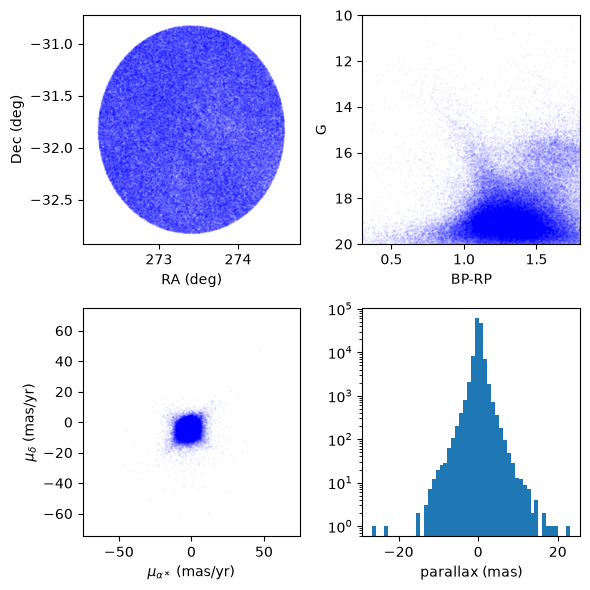

In [4]:
fig, axs = plt.subplots(2, 2, figsize=(6,6))

# Scattering all 3.3M rows four times is slow and memory-hungry; a random
# subsample looks the same for an overview plot.
rng_view = np.random.default_rng(0)
view = rng_view.choice(len(tbl), size=min(200000, len(tbl)), replace=False)
t_view = tbl[view]

axs[0,0].scatter(t_view['ra'], t_view['dec'], fc="b", ec="None", s=2, alpha=0.05, rasterized=True)
axs[1,0].scatter(t_view['pmra'], t_view['pmdec'], fc="b", ec="None", s=2, alpha=0.05, rasterized=True)
axs[0,1].scatter(t_view['phot_bp_mean_mag']-t_view['phot_rp_mean_mag'], t_view['phot_g_mean_mag'], fc="b", ec="None", s=2, alpha=0.05, rasterized=True)
axs[1,1].hist(t_view['parallax'][np.isfinite(t_view['parallax'])], bins=50, log=True)

axs[0,0].set_xlabel(r"RA (deg)")
axs[0,0].set_ylabel(r"Dec (deg)")
axs[1,0].set_xlabel(r"$\mu_{\alpha*}$ (mas/yr)")
axs[1,0].set_ylabel(r"$\mu_{\delta}$ (mas/yr)")
axs[0,1].set_xlabel(r"BP-RP")
axs[0,1].set_ylabel(r"G")
axs[1,1].set_xlabel(r"parallax (mas)")

axs[0,0].set_xlim(ra_range[0],ra_range[1])
axs[0,0].set_ylim(dec_range[0],dec_range[1])
axs[1,0].set_xlim(-75.0,75.0)
axs[1,0].set_ylim(-75.0,75.0)
axs[0,1].set_xlim(0.3,1.8)
axs[0,1].set_ylim(mag_range[1],mag_range[0])

plt.tight_layout()
plt.show()


## Known parameters

We need to know some parameters of the toy Galaxy and GC ahead of time.

In [5]:
pot = agama.Potential("data/MWPotential2014.ini")

mass_gc = 1.72e5 # Msun
coords_gc = SkyCoord(
    ra=273.41125*u.deg,
    dec=-31.82698*u.deg,
    distance=10100*u.pc,
    pm_ra_cosdec=-4.125*u.mas/u.yr, 
    pm_dec=-7.315*u.mas/u.yr,
    radial_velocity=-48.5*u.km/u.s,
    frame="icrs",
)
galactocentric_coords_gc = coords_gc.transform_to(coord.Galactocentric)

#coord_gc = coord.Galactocentric(
#    x=0.0*u.kpc,
#    y=10.0*u.kpc,
#    z=10.0*u.kpc,
#    v_x=-100.0*u.km/u.s,
#    v_y=0.0*u.km/u.s,
#    v_z=-150.0*u.km/u.s
#)
age_gyr = 12.8 # cluster age in Gyr
feh = -0.79

# NOTE: isochrones' MIST_Isochrone.isochrone() takes log10(age/yr), NOT Gyr.
# Passing 12.8 directly asks for a 10^12.8 yr isochrone, which is off the MIST
# grid and returns an EMPTY table (-> NaN mass limits downstream).
log_age = np.log10(age_gyr * 1e9)  # 10.107 for 12.8 Gyr

#skycoord_gc = coord_gc.transform_to(coord.ICRS())
frame = calc_prog_frame(coords_gc)

iso = mist.isochrone(age=log_age, feh=feh) # if you never run this before, it'll take a while
iso_mini = iso["initial_mass"]
iso_color = iso["BP_mag"] - iso["RP_mag"]
iso_mag = iso["G_mag"]

# sanity check: an empty isochrone is the symptom of wrong age units
assert len(iso) > 0, "Empty isochrone -- check that age is log10(yr) and feh is on the grid"
print(f"isochrone rows: {len(iso)}, initial_mass range: {iso_mini.min():.3f} - {iso_mini.max():.3f} Msun")


isochrone rows: 1459, initial_mass range: 0.107 - 0.837 Msun


## Put the observations in the stream frame

The stream PDF lives in the progenitor frame, so the Gaia stars have to be rotated into it before the two PDFs can be compared.


In [6]:
# Transform the Gaia catalogue into the SAME frame as the stream PDF.
#
# GaiaStreamFromProgPDF builds its PDF in the progenitor frame:
#   (phi1, phi2, pm_phi1_cosphi2, pm_phi2, BP-RP, G)
# so the observed stars must be rotated into that frame too -- feeding
# (ra, dec, pmra, pmdec) straight in would compare two different frames.

# --- quality cuts: every dimension of the PDF must be finite ---
g_mag  = np.asarray(tbl["phot_g_mean_mag"], dtype=float)
bp_mag = np.asarray(tbl["phot_bp_mean_mag"], dtype=float)
rp_mag = np.asarray(tbl["phot_rp_mean_mag"], dtype=float)
pmra   = np.asarray(tbl["pmra"], dtype=float)
pmdec  = np.asarray(tbl["pmdec"], dtype=float)

good = (
    np.isfinite(g_mag) & np.isfinite(bp_mag) & np.isfinite(rp_mag)
    & np.isfinite(pmra) & np.isfinite(pmdec)
    & np.isfinite(np.asarray(tbl["pmra_error"], dtype=float))
    & np.isfinite(np.asarray(tbl["pmdec_error"], dtype=float))
    & (g_mag > mag_range[0]) & (g_mag < mag_range[1])
)
# good &= np.asarray(tbl["ruwe"], dtype=float) < 1.4  # optional astrometric cut
print(f"{good.sum()} of {len(tbl)} stars pass the quality cuts")

sub = tbl[good]

# --- rotate positions and proper motions into the progenitor frame ---
obs_icrs = SkyCoord(
    ra=np.asarray(sub["ra"], dtype=float)*u.deg,
    dec=np.asarray(sub["dec"], dtype=float)*u.deg,
    pm_ra_cosdec=np.asarray(sub["pmra"], dtype=float)*u.mas/u.yr,
    pm_dec=np.asarray(sub["pmdec"], dtype=float)*u.mas/u.yr,
    frame="icrs",
)
obs_stream = obs_icrs.transform_to(frame())

phi1 = obs_stream.phi1.wrap_at(180*u.deg).to_value("deg")
phi2 = obs_stream.phi2.to_value("deg")
pm_phi1 = obs_stream.pm_phi1_cosphi2.to_value("mas/yr")
pm_phi2 = obs_stream.pm_phi2.to_value("mas/yr")

print(f"phi1 range: {phi1.min():.2f} to {phi1.max():.2f} deg")
print(f"phi2 range: {phi2.min():.2f} to {phi2.max():.2f} deg")

# --- proper-motion errors in the rotated frame ---
# The frame is a pure rotation of ICRS, so (pm_phi1, pm_phi2) is a rotation
# of (pmra, pmdec) in the tangent plane. Recover that 2x2 rotation per star
# by pushing the unit pm vectors through the same transform.
def _pm_basis(pm_ra_cosdec, pm_dec):
    c = SkyCoord(
        ra=obs_icrs.ra, dec=obs_icrs.dec,
        pm_ra_cosdec=np.full(len(obs_icrs), pm_ra_cosdec)*u.mas/u.yr,
        pm_dec=np.full(len(obs_icrs), pm_dec)*u.mas/u.yr,
        frame="icrs",
    ).transform_to(frame())
    return (c.pm_phi1_cosphi2.to_value("mas/yr"),
            c.pm_phi2.to_value("mas/yr"))

a, b = _pm_basis(1.0, 0.0)  # image of a unit pmra  vector
c, d = _pm_basis(0.0, 1.0)  # image of a unit pmdec vector

sig_pmra  = np.asarray(sub["pmra_error"], dtype=float)
sig_pmdec = np.asarray(sub["pmdec_error"], dtype=float)
# pmra/pmdec correlation is not in the query, so it is neglected here
sig_pm_phi1 = np.sqrt((a*sig_pmra)**2 + (c*sig_pmdec)**2)
sig_pm_phi2 = np.sqrt((b*sig_pmra)**2 + (d*sig_pmdec)**2)

# --- colour error propagated from the BP/RP flux errors ---
def _mag_err(flux, flux_error):
    return (2.5/np.log(10)) * np.asarray(flux_error, dtype=float) \
        / np.asarray(flux, dtype=float)

sig_color = np.sqrt(
    _mag_err(sub["phot_bp_mean_flux"], sub["phot_bp_mean_flux_error"])**2 +
    _mag_err(sub["phot_rp_mean_flux"], sub["phot_rp_mean_flux_error"])**2
)

# --- the (N, 6) arrays the PDFs and the MLE expect ---
# column order: phi1, phi2, pm_phi1, pm_phi2, colour, magnitude
data_all = np.c_[
    phi1, phi2, pm_phi1, pm_phi2,
    np.asarray(sub["phot_bp_mean_mag"], dtype=float)
        - np.asarray(sub["phot_rp_mean_mag"], dtype=float),
    np.asarray(sub["phot_g_mean_mag"], dtype=float),
]

# positional and G-band errors are negligible next to the KDE bandwidths,
# matching the convention used in make_mock.ipynb
err_all = np.c_[
    np.zeros(len(sub)), np.zeros(len(sub)),
    sig_pm_phi1, sig_pm_phi2, sig_color, np.zeros(len(sub)),
]

assert np.all(np.isfinite(data_all)) and np.all(np.isfinite(err_all))
print("data_all:", data_all.shape, " err_all:", err_all.shape)


1481164 of 3263058 stars pass the quality cuts


phi1 range: -1.00 to 1.00 deg
phi2 range: -1.00 to 1.00 deg


data_all: (1481164, 6)  err_all: (1481164, 6)


## Next, let's find streams using the mixture model

### Construct PDFs for the stream and background

In [7]:
# construct PDFs using the same method in Chen+25

t_tot = 1.0 # Gyr
n_steps = 500
seed = 24 # use a different seed to make sure our success is not from luck

# stream PDF using particle spray from progenitor GC
pdf_stream = GaiaStreamFromProgPDF(
    pot, mass_gc, galactocentric_coords_gc, iso_mini, iso_color, iso_mag, 
    mag_cut=mag_cut, frame=frame, t_tot=t_tot, n_steps=n_steps, seed=seed
)
print(f"stream PDF built from {pdf_stream.N} tracers brighter than G = {mag_cut}")

# background PDF from the observed stars, in the same frame as data_all.
# dx is the spatial KDE bandwidth: the 0.5 deg default is meant for a ~20 deg
# field and would smooth this 2 deg field into a handful of cells.
pdf_bg = GaiaBackgroundPDF(
    data_all, field_range=field_range, mag_cut=mag_cut, dx=0.1, seed=seed
)


stream PDF built from 564 tracers brighter than G = 20.0


/Users/coveyk/Library/CloudStorage/Dropbox/python/StarStream-src/StarStream/agama_stream.py:33: FutureWarning: forceDeriv is deprecated, use Potential.eval(..., der=True) instead
  der = pot_host.forceDeriv(np.column_stack([x,y,z]))[1]
/Users/coveyk/Library/CloudStorage/Dropbox/python/StarStream-src/StarStream/agama_stream.py:138: FutureWarning: Consider using separateTime=True, which would enable optimized output storage: timestamps for all orbits put into a single 2d numpy array, and trajectories - into a single 3d array (see docstring for details). This will become the default option in a future version. Or add separateTime=False if you want to keep the deprecated format and suppress this warning.
  xv_stream = np.vstack(agama.orbit(potential=pot_tot,
998 orbits complete (9156 orbits/s)


### Estimate best-fit stream fraction using MLE

In [8]:
fbest, prob, frac_list, dlnL_list = optimize_mle(data_all, err_all, pdf_stream, pdf_bg)

print(f"The best-fit stream fraction from MLE is {fbest:.2e}")
print(f"Delta lnL at the best fit: {np.max(dlnL_list):.1f}")


The best-fit stream fraction from MLE is 5.01e-05
Delta lnL at the best fit: 2055.5


### Detection result

In [9]:
pth = 0.4 # threshold membership probability

# NOTE: `label_all` only exists for the mock dataset, where the true members
# are known. For real Gaia data there is no truth column, so we can only
# report how many stars the mixture model assigns to the stream.
mask_detect = prob > pth

print(f"Stars with p > {pth}: {np.sum(mask_detect)} of {len(prob)}")
print(f"Expected number of stream stars from f_best: {fbest*len(prob):.1f}")
if np.sum(mask_detect) > 0:
    print(f"G range of the candidates: "
          f"{data_all[mask_detect,5].min():.2f} to {data_all[mask_detect,5].max():.2f}")


Stars with p > 0.4: 71 of 1481164
Expected number of stream stars from f_best: 74.2
G range of the candidates: 16.90 to 19.99


### Some visualizations of the detection

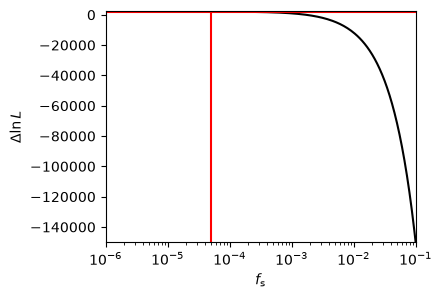

In [10]:
fig, ax0 = plt.subplots(1, 1, figsize=(4,3))

ax0.plot(frac_list, dlnL_list, c="k")

ax0.axvline(fbest, c="r")
ax0.axhline(np.max(dlnL_list), c="r")

ax0.set_xlabel(r"$f_{\rm s}$")
ax0.set_ylabel(r"$\Delta \ln L$")
ax0.set_xscale("log")
ax0.set_xlim(frac_list[0], frac_list[-1])
# guard against a non-detection, where max(dlnL) can be <= 0
ax0.set_ylim(min(0.0, np.min(dlnL_list)), max(np.max(dlnL_list)*1.2, 1.0))

plt.show()


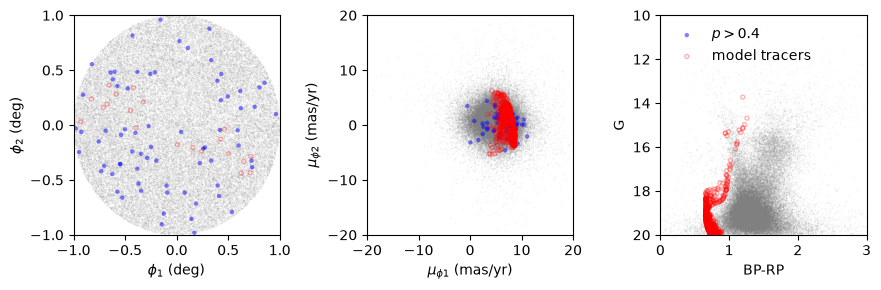

In [11]:
fig, [ax0, ax1, ax2] = plt.subplots(1, 3, figsize=(9,3))

# all field stars (subsampled so the plot stays light)
rng_plot = np.random.default_rng(0)
show = rng_plot.choice(len(data_all), size=min(50000, len(data_all)), replace=False)

ax0.scatter(data_all[show,0], data_all[show,1], fc="gray", ec="None", s=1, alpha=0.1)
ax1.scatter(data_all[show,2], data_all[show,3], fc="gray", ec="None", s=1, alpha=0.1)
ax2.scatter(data_all[show,4], data_all[show,5], fc="gray", ec="None", s=1, alpha=0.1)

# stream candidates
ax0.scatter(data_all[mask_detect,0], data_all[mask_detect,1], fc="b", ec="None", s=10, alpha=0.5)
ax1.scatter(data_all[mask_detect,2], data_all[mask_detect,3], fc="b", ec="None", s=10, alpha=0.5)
ax2.scatter(data_all[mask_detect,4], data_all[mask_detect,5], fc="b", ec="None", s=10, alpha=0.5,
            label=rf"$p > {pth}$")

# the model stream tracers, for comparison
ax0.scatter(pdf_stream.data[:,0], pdf_stream.data[:,1], ec="r", fc="None", s=8, alpha=0.3)
ax1.scatter(pdf_stream.data[:,2], pdf_stream.data[:,3], ec="r", fc="None", s=8, alpha=0.3)
ax2.scatter(pdf_stream.data[:,4], pdf_stream.data[:,5], ec="r", fc="None", s=8, alpha=0.3,
            label=r"model tracers")

ax2.legend(loc="upper left", frameon=False)

ax0.set_xlabel(r"$\phi_1$ (deg)")
ax0.set_ylabel(r"$\phi_2$ (deg)")
ax1.set_xlabel(r"$\mu_{\phi1}$ (mas/yr)")
ax1.set_ylabel(r"$\mu_{\phi2}$ (mas/yr)")
ax2.set_xlabel(r"BP-RP")
ax2.set_ylabel(r"G")

ax0.set_xlim(*field_range)
ax0.set_ylim(*field_range)
ax1.set_xlim(-20.0,20.0)
ax1.set_ylim(-20.0,20.0)
ax2.set_xlim(0.0,3.0)
ax2.set_ylim(mag_range[1],mag_range[0])

plt.tight_layout()
plt.show()
